# Q-AstroEdge: Quantum Edge Detection per Immagini Astronomiche
**Qiskit Fall Fest 2026 — Catania | Traccia: Quantum per l'Astrofisica (INAF)**

### Obiettivo del Progetto
L'analisi morfologica di galassie, nebulose e sorgenti celesti richiede l'identificazione precisa dei contorni (*edge detection*). Su immagini ad altissima risoluzione, i filtri convolutivi classici (come **Sobel** e **Canny**) richiedono $\mathcal{O}(N^2)$ operazioni sequenziali.

In questo notebook implementiamo e confrontiamo in **Qiskit** due paradigmi quantistici basati sulla letteratura recente:
1. **QHED (*Quantum Hadamard Edge Detection*):** codifica delle intensità nelle ampiezze di stato (QPIE) ed estrazione parallela dei gradienti tramite porta di Hadamard e shift ciclici.
2. **DTQWS (*Discrete-Time Quantum Walk Search*):** Quantum Walk a tempo discreto su blocchi $2 \times 2$ con circuito NISQ-friendly a **4 qubit** e moneta truccata $\mathcal{C}_G$, testate sia in condizioni ideali sia con un modello di rumore realistico IBM.

**Riferimenti bibliografici:**
* *A Fully Quantum Algorithm for Image Edge Detection* (F. Sun, 2026) — direzione del gradiente e allineamento sul lato scuro.
* *Quantum walk search based edge detection of images* (P. R. Giri et al., 2025) — architettura DTQWS a 4 qubit su blocchi $2 \times 2$ con moneta $\mathcal{C}_G$.

In [12]:
!pip install -q qiskit qiskit-aer scikit-image matplotlib numpy scipy

import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform, filters, metrics
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import StatePreparation, UnitaryGate
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error

print("Ambiente Qiskit + Image Processing pronto!")

Ambiente Qiskit + Image Processing pronto!


## 1. Dataset Astronomico e Baseline Classica (Filtro di Sobel)
Utilizziamo un ritaglio dell'**Hubble Deep Field** ridimensionato a $64 \times 64$ pixel ($2^6 \times 2^6 = 4096$ pixel totali) e normalizzato in scala di grigi $[0, 1]$. Come riferimento classico (*ground truth*) calcoliamo la mappa dei gradienti tramite il **filtro di Sobel**.

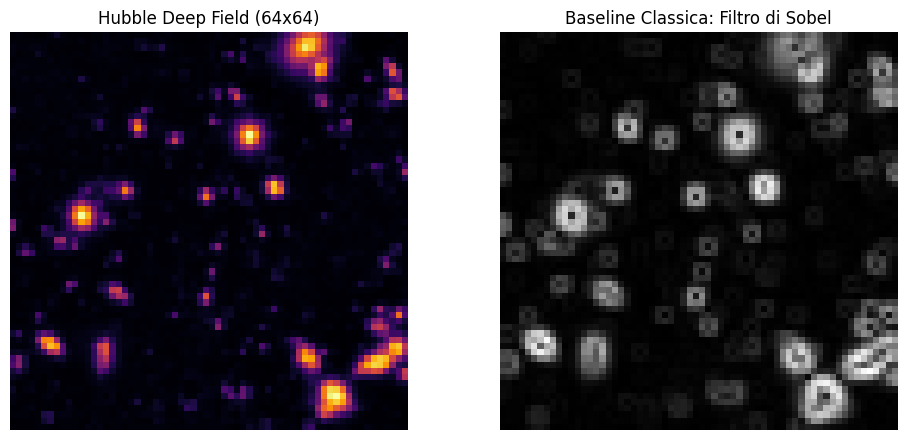

In [13]:
# 1. Carichiamo l'immagine Hubble Deep Field, ritagliamo una regione ricca di galassie e convertiamo in scala di grigi
raw_astro = data.hubble_deep_field()

# Ritaglio centrale 256x256 e conversione in scala di grigi [0, 1]
crop = raw_astro[100:356, 100:356]
gray_astro = np.mean(crop, axis=-1) / 255.0

# Ridimensioniamo a N x N con N = 64 (2^6 x 2^6 = 4096 pixel -> 12 qubit totali)
IMG_SIZE = 64
img = transform.resize(gray_astro, (IMG_SIZE, IMG_SIZE), anti_aliasing=True)

# Normalizziamo l'intensità tra 0 e 1
img = (img - img.min()) / (img.max() - img.min())

# 2. Baseline Classica: Filtro di Sobel
edges_sobel = filters.sobel(img)
edges_sobel = edges_sobel / edges_sobel.max()

# Visualizzazione affiancata
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(img, cmap='inferno')
axes[0].set_title(f'Hubble Deep Field ({IMG_SIZE}x{IMG_SIZE})')
axes[0].axis('off')

axes[1].imshow(edges_sobel, cmap='gray')
axes[1].set_title('Baseline Classica: Filtro di Sobel')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 2. Metodo 1: Quantum Hadamard Edge Detection (QHED — 12 Qubit)
L'immagine $64 \times 64$ viene codificata in un registro di $n = 12$ qubit tramite **Quantum Probability Image Encoding (QPIE)**:
$$|\psi_{\text{in}}\rangle = \sum_{i=0}^{2^{12}-1} c_i |i\rangle$$
Applicando una singola porta di **Hadamard** ($H$) sul qubit meno significativo, gli stati dispari restituiscono direttamente le differenze di intensità tra pixel adiacenti $(c_{2i} - c_{2i+1})/\sqrt{2}$ in parallelo. Combinando una scansione diretta, una scansione shiftata ciclicamente e la trasposta dell'immagine, otteniamo i gradienti orizzontali e verticali completi.

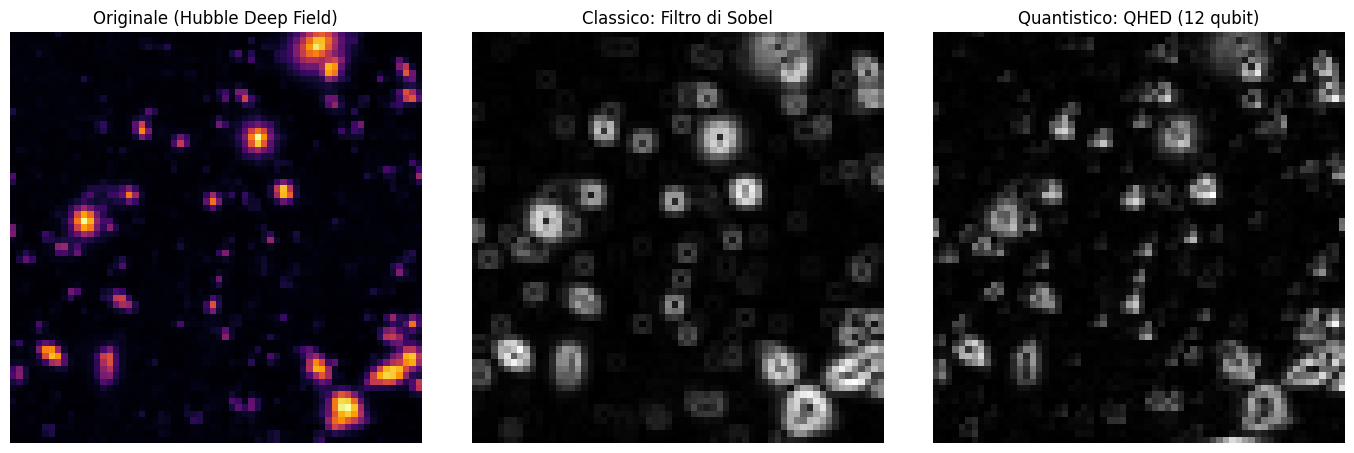

In [14]:
# Algoritmo 1 — Quantum Hadamard Edge Detection (QHED)
from qiskit.quantum_info import Statevector

def qhed_1d_scan(image_2d):
    """
    Esegue una scansione QHED orizzontale (riga per riga appiattita) usando Qiskit Statevector.
    Combina il passaggio diretto (coppie pari-dispari) e il passaggio shiftato (coppie dispari-pari).
    """
    H_dim, W_dim = image_2d.shape
    flat = image_2d.flatten().astype(float)
    n_qubits = int(np.log2(len(flat)))

    def run_h_pass(vec):
        norm = np.linalg.norm(vec)
        if norm == 0:
            return np.zeros_like(vec)
        amplitudes = vec / norm

        qc = QuantumCircuit(n_qubits)
        qc.append(StatePreparation(amplitudes), range(n_qubits))
        # Porta di Hadamard sul qubit meno significativo (qubit 0)
        qc.h(0)

        sv = Statevector.from_instruction(qc).data
        # Estraiamo gli stati dispari (q0 == 1) che contengono (c_{2i} - c_{2i+1}) / sqrt(2)
        odd_amps = np.abs(sv[1::2]) * norm * np.sqrt(2)
        return odd_amps

    # Passaggio 1: gradienti tra (0,1), (2,3), ...
    grad_even = run_h_pass(flat)

    # Passaggio 2: shift ciclico di 1 pixel per catturare (1,2), (3,4), ...
    flat_shifted = np.roll(flat, -1)
    grad_odd = run_h_pass(flat_shifted)

    # Ricostruiamo il vettore gradiente completo di lunghezza N^2
    full_grad = np.zeros_like(flat)
    full_grad[0::2] = grad_even
    full_grad[1::2] = grad_odd

    return full_grad.reshape((H_dim, W_dim))

# Calcoliamo il gradiente QHED orizzontale e verticale
qhed_x = qhed_1d_scan(img)
qhed_y = qhed_1d_scan(img.T).T

# Magnitudine totale del gradiente QHED
edges_qhed = np.sqrt(qhed_x**2 + qhed_y**2)
edges_qhed = edges_qhed / edges_qhed.max()

# Visualizzazione confronto Sobel vs QHED
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(img, cmap='inferno')
axes[0].set_title('Originale (Hubble Deep Field)')
axes[0].axis('off')

axes[1].imshow(edges_sobel, cmap='gray')
axes[1].set_title('Classico: Filtro di Sobel')
axes[1].axis('off')

axes[2].imshow(edges_qhed, cmap='gray')
axes[2].set_title('Quantistico: QHED (12 qubit)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 3. Metodo 2: Discrete-Time Quantum Walk Search (DTQWS — 4 Qubit)
Poiché QHED limita teoricamente la probabilità di successo a $\bar{p}_s \le 0.50$ e perde contrasto sui bordi deboli, implementiamo una **Quantum Walk Search** su blocchi $2 \times 2$ (cicli di 4 vertici) utilizzando solo **4 qubit** (`2 coin` + `2 vertex`) e $t = 2$ iterazioni dell'operatore $\mathcal{U} = S \cdot \mathcal{C}_G$.

* **Marcatura direzionale:** i pixel di bordo vengono marcati sul lato scuro della transizione di intensità, per evitare l'ispessimento dei nuclei galattici.
* **Simulazione Ideale vs Rumorosa:** confrontiamo il simulatore ideale con un `NoiseModel` depolarizzante (errori sui gate a 1 e 2 qubit) misurando la probabilità media di successo $\bar{p}_s$.

Probabilità media di successo (Ideale):   p_s = 0.792
Probabilità media di successo (Rumoroso): p_s = 0.558


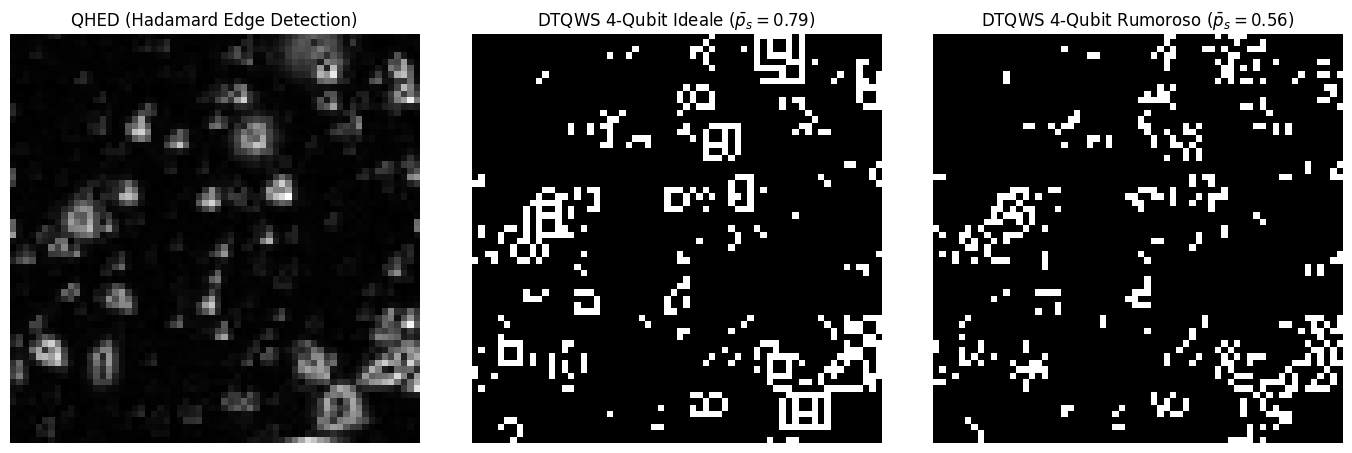

In [15]:
# Algoritmo 2 — Quantum Walk Search (DTQWS) a 4 qubit (Ideale vs Rumoroso)

def build_dtqws_block_circuit(marked_indices, s=0.1, t=2):
    """
    Costruisce il circuito Qiskit a 4 qubit (2 vertice + 2 moneta) per un blocco 2x2
    con moneta modificata C_G e self-loop di peso s (Sez. II-III di Giri et al., 2025).
    """
    # Stato iniziale della moneta (4 dimensioni: left, right, self-loop 1, self-loop 2)
    # Pesi: 1 per left, 1 per right, sqrt(s/2) per ciascuno dei due self-loop
    coin_vec = np.array([1.0, 1.0, np.sqrt(s / 2.0), np.sqrt(s / 2.0)])
    coin_vec = coin_vec / np.linalg.norm(coin_vec)

    # Operatore di diffusione di Grover C sullo spazio della moneta (4x4)
    C_diff = 2.0 * np.outer(coin_vec, coin_vec) - np.eye(4)

    # Costruzione della matrice unitaria 16x16 per la moneta modificata C_G:
    # Per i vertici marcati (bordi), inverte il segno sui due stati di self-loop (indici 2 e 3)
    C_G_mat = np.zeros((16, 16), dtype=complex)
    for v in range(4):
        block = C_diff.copy()
        if v in marked_indices:
            block[:, 2] = -block[:, 2]
            block[:, 3] = -block[:, 3]
        # Nota: in Qiskit il registro v è nei qubit più significativi (v*4 : (v+1)*4)
        C_G_mat[v*4:(v+1)*4, v*4:(v+1)*4] = block

    # Costruzione della matrice di shift flip-flop S (16x16) su ciclo di 4 vertici:
    # c=0 (right): |v, 0> -> |(v+1)%4, 1>
    # c=1 (left):  |v, 1> -> |(v-1)%4, 0>
    # c=2,3 (self-loops): |v, c> -> |v, c>
    S_mat = np.zeros((16, 16), dtype=complex)
    for v in range(4):
        # right -> left sul vicino successivo
        S_mat[((v + 1) % 4) * 4 + 1, v * 4 + 0] = 1.0
        # left -> right sul vicino precedente
        S_mat[((v - 1) % 4) * 4 + 0, v * 4 + 1] = 1.0
        # self-loops invariati
        S_mat[v * 4 + 2, v * 4 + 2] = 1.0
        S_mat[v * 4 + 3, v * 4 + 3] = 1.0

    # Un singolo passo U = S * C_G
    U_step = S_mat @ C_G_mat
    U_gate = UnitaryGate(U_step, label="U_DTQWS")

    qc = QuantumCircuit(4, 2) # q[0..1] = coin, q[2..3] = vertex
    # 1. Sovrapposizione uniforme sui 4 vertici
    qc.h([2, 3])
    # 2. Preparazione stato iniziale della moneta
    qc.append(StatePreparation(coin_vec), [0, 1])

    # 3. Evoluzione per t passi
    for _ in range(t):
        qc.append(U_gate, [0, 1, 2, 3])

    # 4. Misura solo i 2 qubit dei vertici (q[2], q[3])
    qc.measure([2, 3], [0, 1])
    return qc

# Creiamo il simulatore ideale e un simulatore con rumore realistico IBM (depolarizzazione)
sim_ideal = AerSimulator()

noise_model = NoiseModel()
error_1q = depolarizing_error(0.002, 1)  # 0.2% errore gate singolo qubit
error_2q = depolarizing_error(0.015, 2)  # 1.5% errore gate a 2 qubit (CX)
noise_model.add_all_qubit_quantum_error(error_1q, ['u', 'u1', 'u2', 'u3', 'rx', 'ry', 'rz', 'h'])
noise_model.add_all_qubit_quantum_error(error_2q, ['cx'])
sim_noisy = AerSimulator(noise_model=noise_model)

# Aggiornamento Cella 4: Marcatura direzionale sul lato scuro + Binarizzazione post-misura
def run_dtqws_image(image_2d, a_th=0.08, shots=256):
    H_dim, W_dim = image_2d.shape
    edges_ideal = np.zeros_like(image_2d)
    edges_noisy = np.zeros_like(image_2d)

    ps_ideal_list = []
    ps_noisy_list = []

    cycle_coords = [(0, 0), (0, 1), (1, 1), (1, 0)]
    basis_gates = ['u', 'cx']

    for r in range(0, H_dim, 2):
        for c in range(0, W_dim, 2):
            block = image_2d[r:r+2, c:c+2]
            vals = [block[dr, dc] for dr, dc in cycle_coords]

            # Marcatura direzionale: segna il lato scuro della transizione (Paper 1, Sez. III-C)
            marked = []
            for idx in range(4):
                diff_next = vals[(idx + 1) % 4] - vals[idx]
                diff_prev = vals[(idx - 1) % 4] - vals[idx]
                if max(diff_next, diff_prev) >= a_th:
                    marked.append(idx)

            if not marked:
                continue

            qc = build_dtqws_block_circuit(marked, s=0.1, t=2)
            t_qc = transpile(qc, basis_gates=basis_gates, optimization_level=1)

            counts_id = sim_ideal.run(t_qc, shots=shots).result().get_counts()
            counts_ns = sim_noisy.run(t_qc, shots=shots).result().get_counts()

            p_succ_id = 0.0
            p_succ_ns = 0.0
            for idx, (dr, dc) in enumerate(cycle_coords):
                bitstr = format(idx, '02b')
                prob_id = counts_id.get(bitstr, 0) / shots
                prob_ns = counts_ns.get(bitstr, 0) / shots
                edges_ideal[r + dr, c + dc] = prob_id
                edges_noisy[r + dr, c + dc] = prob_ns
                if idx in marked:
                    p_succ_id += prob_id
                    p_succ_ns += prob_ns

            ps_ideal_list.append(p_succ_id)
            ps_noisy_list.append(p_succ_ns)

    return edges_ideal, edges_noisy, np.mean(ps_ideal_list), np.mean(ps_noisy_list)

edges_qws_ideal, edges_qws_noisy, ps_id, ps_ns = run_dtqws_image(img, a_th=0.08, shots=256)

# Binarizzazione post-processing (come in Sez. III di Giri et al., 2025)
bin_qws_ideal = (edges_qws_ideal > 0.25).astype(float)
bin_qws_noisy = (edges_qws_noisy > 0.25).astype(float)

print(f"Probabilità media di successo (Ideale):   p_s = {ps_id:.3f}")
print(f"Probabilità media di successo (Rumoroso): p_s = {ps_ns:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(edges_qhed, cmap='gray')
axes[0].set_title('QHED (Hadamard Edge Detection)')
axes[0].axis('off')

axes[1].imshow(bin_qws_ideal, cmap='gray')
axes[1].set_title(f'DTQWS 4-Qubit Ideale ($\\bar{{p}}_s = {ps_id:.2f}$)')
axes[1].axis('off')

axes[2].imshow(bin_qws_noisy, cmap='gray')
axes[2].set_title(f'DTQWS 4-Qubit Rumoroso ($\\bar{{p}}_s = {ps_ns:.2f}$)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 4. Benchmark Quantitativo, Analisi Risorse e Schema Circuitale
Valutiamo quantitativamente la qualità dei contorni estratti rispetto a Sobel tramite **F1-Score**, **SSIM** e **PSNR**, analizzando infine la profondità, il numero di gate `CX` e l'architettura del circuito DTQWS a 4 qubit.

=== TABELLA RIASSUNTIVA BENCHMARK (vs Ground Truth Sobel) ===
Metodo                    | F1-Score   | SSIM       | PSNR (dB)  | Prob. Successo p_s
--------------------------------------------------------------------------------
QHED (12 qubit)           | 0.695      | 0.708      | 19.73      | <= 0.500 (teorico)
DTQWS 4-Qubit (Ideale)    | 0.534      | 0.381      | 9.27       | 0.792
DTQWS 4-Qubit (Rumoroso)  | 0.433      | 0.323      | 8.76       | 0.558

=== RISORSE HARDWARE CIRCUITO DTQWS (1 BLOCCO 2x2) ===
Numero Qubit:        4 (2 posizione + 2 moneta)
Circuit Depth:       365
Gate a 2 qubit (CX): 184
Gate a 1 qubit (U):  308


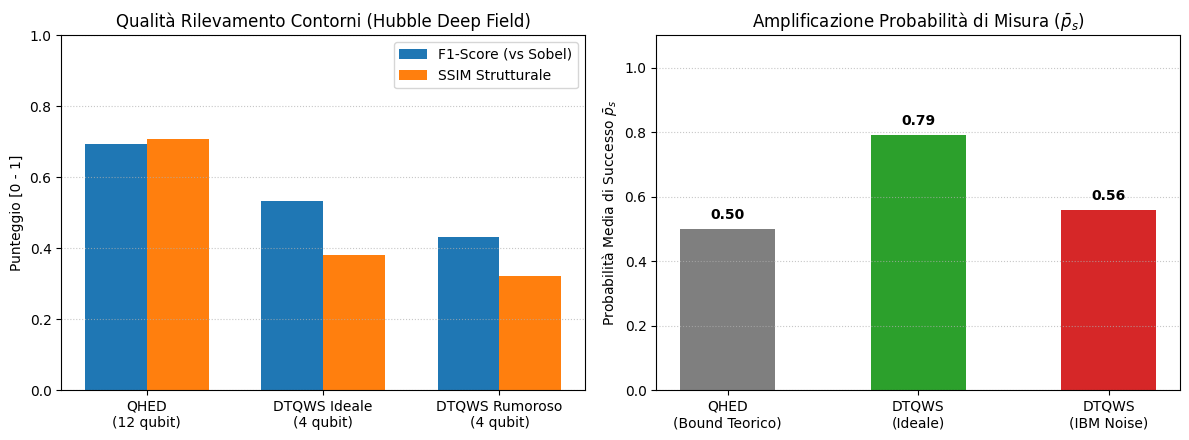

In [16]:
# Benchmark Quantitativo, Analisi Risorse Hardware e Diagramma Circuito

# 1. Prepariamo le mappe binarie confrontabili con la ground truth di Sobel
gt_sobel_bin = (edges_sobel > 0.25).astype(float)
qhed_bin = (edges_qhed > 0.25).astype(float)

def compute_edge_metrics(pred_bin, gt_bin, pred_cont, gt_cont):
    # Precision, Recall e F1-Score sui pixel di bordo (1 = bordo, 0 = sfondo)
    tp = np.sum((pred_bin == 1) & (gt_bin == 1))
    fp = np.sum((pred_bin == 1) & (gt_bin == 0))
    fn = np.sum((pred_bin == 0) & (gt_bin == 1))

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    # SSIM e PSNR sulle mappe normalizzate [0, 1]
    ssim_val = metrics.structural_similarity(gt_cont, pred_cont, data_range=1.0)
    psnr_val = metrics.peak_signal_noise_ratio(gt_cont, pred_cont, data_range=1.0)
    return f1, ssim_val, psnr_val

f1_qhed, ssim_qhed, psnr_qhed = compute_edge_metrics(qhed_bin, gt_sobel_bin, edges_qhed, edges_sobel)
f1_id, ssim_id, psnr_id = compute_edge_metrics(bin_qws_ideal, gt_sobel_bin, bin_qws_ideal, gt_sobel_bin)
f1_ns, ssim_ns, psnr_ns = compute_edge_metrics(bin_qws_noisy, gt_sobel_bin, bin_qws_noisy, gt_sobel_bin)

print("=== TABELLA RIASSUNTIVA BENCHMARK (vs Ground Truth Sobel) ===")
print(f"{'Metodo':<25} | {'F1-Score':<10} | {'SSIM':<10} | {'PSNR (dB)':<10} | {'Prob. Successo p_s'}")
print("-" * 80)
print(f"{'QHED (12 qubit)':<25} | {f1_qhed:<10.3f} | {ssim_qhed:<10.3f} | {psnr_qhed:<10.2f} | {'<= 0.500 (teorico)'}")
print(f"{'DTQWS 4-Qubit (Ideale)':<25} | {f1_id:<10.3f} | {ssim_id:<10.3f} | {psnr_id:<10.2f} | {ps_id:.3f}")
print(f"{'DTQWS 4-Qubit (Rumoroso)':<25} | {f1_ns:<10.3f} | {ssim_ns:<10.3f} | {psnr_ns:<10.2f} | {ps_ns:.3f}")

# 2. Analisi delle risorse del circuito DTQWS a 4 qubit (NISQ-friendly)
sample_dtqws = build_dtqws_block_circuit([0, 1], s=0.1, t=2)
t_sample = transpile(sample_dtqws, basis_gates=['u', 'cx'], optimization_level=2)
ops_count = t_sample.count_ops()

print("\n=== RISORSE HARDWARE CIRCUITO DTQWS (1 BLOCCO 2x2) ===")
print(f"Numero Qubit:        {sample_dtqws.num_qubits} (2 posizione + 2 moneta)")
print(f"Circuit Depth:       {t_sample.depth()}")
print(f"Gate a 2 qubit (CX): {ops_count.get('cx', 0)}")
print(f"Gate a 1 qubit (U):  {ops_count.get('u', 0)}")

# 3. Grafico finale riassuntivo per le slide (Metriche + Complessità)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

methods = ['QHED\n(12 qubit)', 'DTQWS Ideale\n(4 qubit)', 'DTQWS Rumoroso\n(4 qubit)']
f1_scores = [f1_qhed, f1_id, f1_ns]
ssim_scores = [ssim_qhed, ssim_id, ssim_ns]

x = np.arange(len(methods))
width = 0.35

axes[0].bar(x - width/2, f1_scores, width, label='F1-Score (vs Sobel)', color='#1f77b4')
axes[0].bar(x + width/2, ssim_scores, width, label='SSIM Strutturale', color='#ff7f0e')
axes[0].set_ylabel('Punteggio [0 - 1]')
axes[0].set_title('Qualità Rilevamento Contorni (Hubble Deep Field)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(methods)
axes[0].set_ylim(0, 1.0)
axes[0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0].legend()

# Confronto Probabilità di Successo p_s (come Sez. V di Giri et al., 2025)
ps_methods = ['QHED\n(Bound Teorico)', 'DTQWS\n(Ideale)', 'DTQWS\n(IBM Noise)']
ps_values = [0.50, ps_id, ps_ns]
colors_ps = ['#7f7f7f', '#2ca02c', '#d62728']

bars = axes[1].bar(ps_methods, ps_values, color=colors_ps, width=0.5)
axes[1].set_ylabel('Probabilità Media di Successo $\\bar{p}_s$')
axes[1].set_title('Amplificazione Probabilità di Misura ($\\bar{p}_s$)')
axes[1].set_ylim(0, 1.1)
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
for bar, val in zip(bars, ps_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.03, f"{val:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("Q_AstroEdge_Benchmark.png", dpi=200)
plt.show()

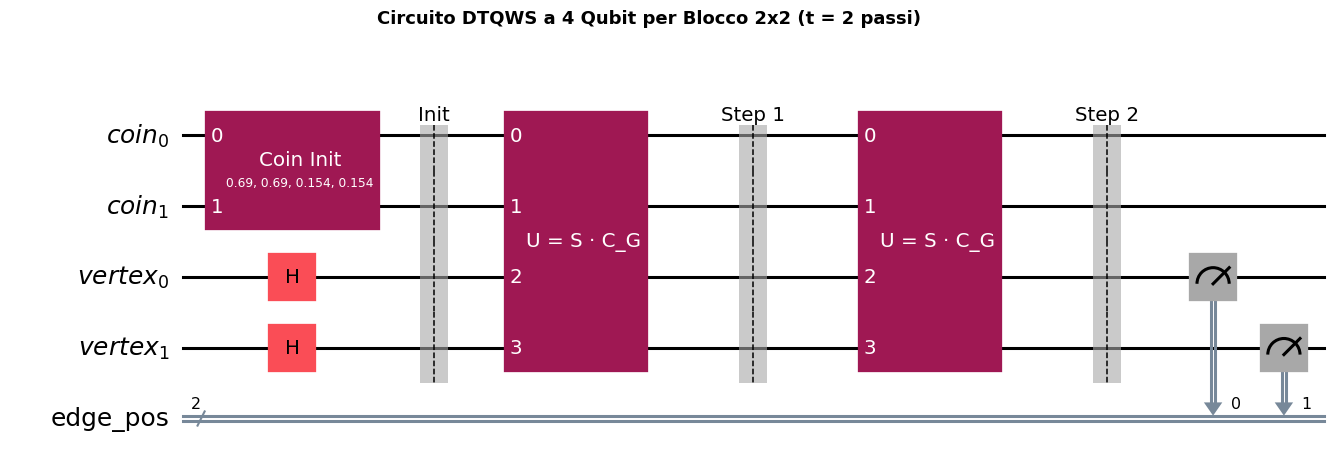

In [17]:
# Rappresentazione grafica del circuito DTQWS

def build_dtqws_diagram_circuit(marked_indices=[0, 1], s=0.1, t=2):
    coin_reg = QuantumRegister(2, name='coin')
    vert_reg = QuantumRegister(2, name='vertex')
    meas_reg = ClassicalRegister(2, name='edge_pos')

    qc = QuantumCircuit(coin_reg, vert_reg, meas_reg)

    # 1. Preparazione stato iniziale
    coin_vec = np.array([1.0, 1.0, np.sqrt(s / 2.0), np.sqrt(s / 2.0)])
    coin_vec = coin_vec / np.linalg.norm(coin_vec)

    qc.append(StatePreparation(coin_vec, label="Coin Init"), coin_reg)
    qc.h(vert_reg)
    qc.barrier(label="Init")

    # 2. Costruzione operatore passo U = S * C_G
    C_diff = 2.0 * np.outer(coin_vec, coin_vec) - np.eye(4)
    C_G_mat = np.zeros((16, 16), dtype=complex)
    for v in range(4):
        block = C_diff.copy()
        if v in marked_indices:
            block[:, 2] = -block[:, 2]
            block[:, 3] = -block[:, 3]
        C_G_mat[v*4:(v+1)*4, v*4:(v+1)*4] = block

    S_mat = np.zeros((16, 16), dtype=complex)
    for v in range(4):
        S_mat[((v + 1) % 4) * 4 + 1, v * 4 + 0] = 1.0
        S_mat[((v - 1) % 4) * 4 + 0, v * 4 + 1] = 1.0
        S_mat[v * 4 + 2, v * 4 + 2] = 1.0
        S_mat[v * 4 + 3, v * 4 + 3] = 1.0

    U_gate = UnitaryGate(S_mat @ C_G_mat, label="U = S · C_G")

    # 3. Evoluzione per t=2 passi della Quantum Walk
    for step in range(1, t + 1):
        qc.append(U_gate, [coin_reg[0], coin_reg[1], vert_reg[0], vert_reg[1]])
        qc.barrier(label=f"Step {step}")

    # 4. Misura dei qubit di posizione
    qc.measure(vert_reg, meas_reg)
    return qc

dtqws_circuit_fig = build_dtqws_diagram_circuit()

# Disegno grafico con stile 'iqp' (colori classici IBM Quantum) su una singola riga
fig = dtqws_circuit_fig.draw(output='mpl', style='iqp', fold=-1, scale=1.1)
fig.suptitle("Circuito DTQWS a 4 Qubit per Blocco 2x2 (t = 2 passi)", fontsize=13, fontweight='bold', y=1.02)
fig.savefig("DTQWS_Circuit_Diagram.png", dpi=300, bbox_inches='tight')
display(fig)